In [22]:
   !pip install shap


In [23]:
import zipfile
import os
import pandas as pd
import urllib.request

zip_path = "archive.zip"
csv_path = "/content/PhiUSIIL_Phishing_URL_Dataset.csv"

# Téléchargement et extraction du dataset s'il n'est pas déjà présent
if not os.path.exists(csv_path):
    if not os.path.exists(zip_path) and not os.path.exists("/archive.zip"):
        print("Téléchargement du dataset d'origine depuis UCI...")
        # URL directe et stable du dataset d'origine depuis le dépôt officiel de l'UCI
        url = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
        try:
            # Envoi d'un User-Agent pour éviter le blocage par l'hébergeur
            opener = urllib.request.build_opener()
            opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
            urllib.request.install_opener(opener)
            urllib.request.urlretrieve(url, zip_path)
            print("Téléchargement réussi !")
        except Exception as e:
            print(f"Erreur lors du téléchargement : {e}")
            print("Veuillez importer manuellement le fichier 'archive.zip' dans vos fichiers Colab.")

    final_zip_path = "/archive.zip" if os.path.exists("/archive.zip") else zip_path

    if os.path.exists(final_zip_path):
        print(f"Extraction de {final_zip_path}...")
        with zipfile.ZipFile(final_zip_path, 'r') as zip_ref:
            zip_ref.extractall("/content")

# Lecture et validation de la structure du dataset
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Données chargées avec succès !")
    print(df.head())
    print(df.shape)
else:
    print(f"Impossible de charger {csv_path}. Le téléchargement ou l'extraction a échoué.")

Données chargées avec succès !
     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...    0   
1               100.0              0.666667    

In [24]:
df.info()
df.isna().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [25]:
df['IsPhishing'] = 1 - df['label']      # 1 becomes 0, 0 becomes 1
df['IsPhishing'].value_counts(normalize=True)

,proportion
IsPhishing,
0,0.571895
1,0.428105


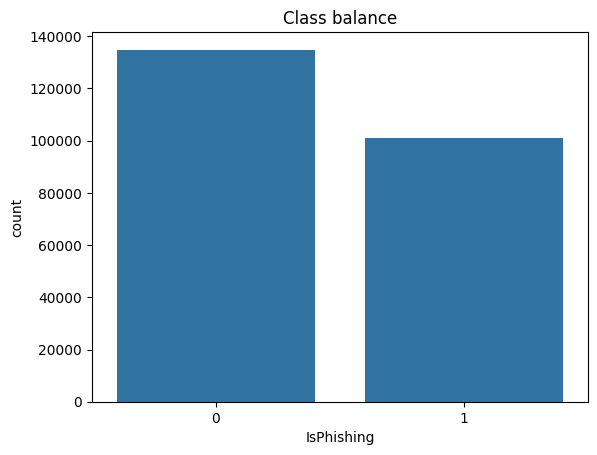

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1) Class balance
sns.countplot(x='IsPhishing', data=df)
plt.title("Class balance")
plt.show()

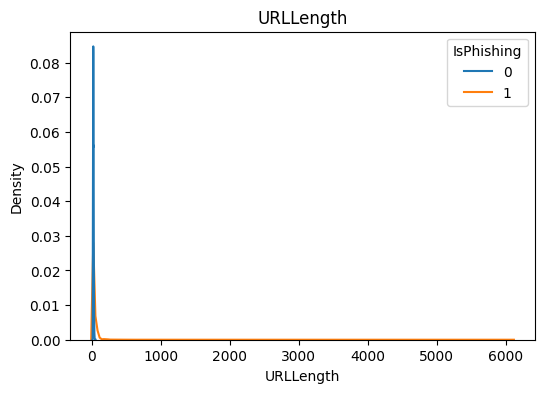

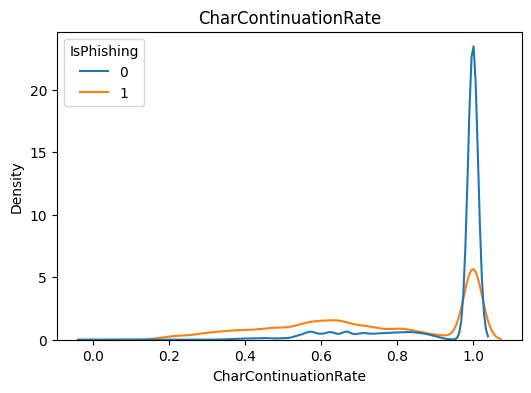

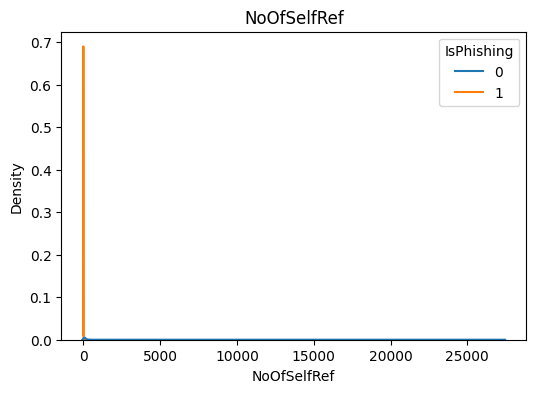

In [27]:
# 2) Numeric features: compare the two classes
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

for col in num_cols:                       # LOOP: one plot per feature
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue='IsPhishing', common_norm=False)
    plt.title(col)
    plt.show()

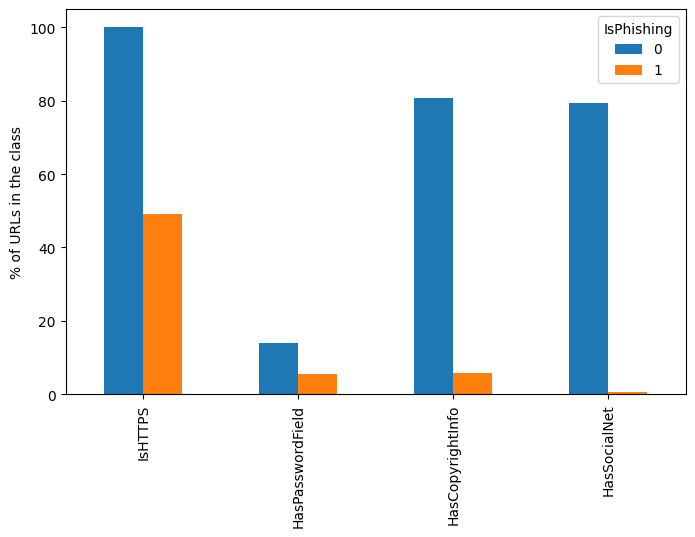

In [28]:
# 3) Binary indicators: % of each class that has the property
bin_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']

prevalence = df.groupby('IsPhishing')[bin_cols].mean() * 100
prevalence.T.plot(kind='bar', figsize=(8,5))
plt.ylabel("% of URLs in the class")
plt.show()

In [29]:
drop_cols = ['FILENAME','URL','Domain','TLD','Title','label','URLSimilarityIndex']
X = df.drop(columns=drop_cols + ['IsPhishing'])
y = df['IsPhishing']

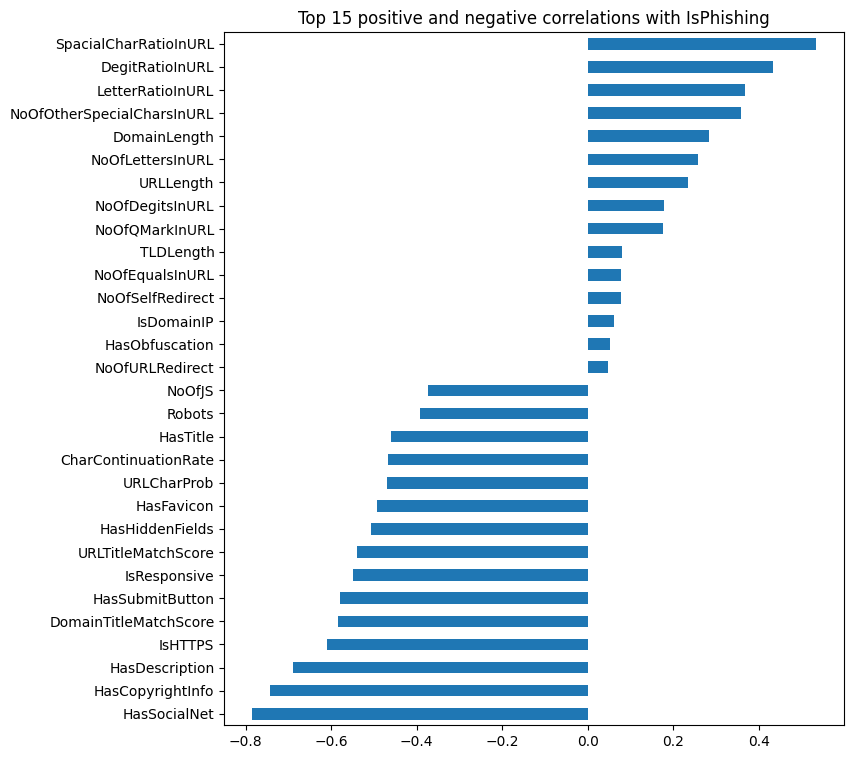

In [30]:
corr = X.corrwith(y)                       # Pearson correlation of each feature with y
top_pos = corr.sort_values(ascending=False).head(15)
top_neg = corr.sort_values().head(15)

top = pd.concat([top_pos, top_neg]).sort_values()
top.plot(kind='barh', figsize=(8,9))
plt.title("Top 15 positive and negative correlations with IsPhishing")
plt.show()

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Garantie que la variable cible 'IsPhishing' est correctement créée à partir de 'label'
if 'IsPhishing' not in df.columns and 'label' in df.columns:
    df['IsPhishing'] = 1 - df['label']

# Définition des caractéristiques (X) et de la cible (y)
drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'URLSimilarityIndex']
# On ne supprime que les colonnes qui existent réellement dans le DataFrame
existing_drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(columns=existing_drop_cols + ['IsPhishing'])
y = df['IsPhishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

In [32]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),        # LEARN the mean and std on train, then apply
    columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),             # only APPLY, never learn
    columns=X_test.columns, index=X_test.index
)

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

models = {
    "M1_None":     LogisticRegression(penalty=None, solver='lbfgs', max_iter=500, random_state=42),
    "M2_L2_C0.001":LogisticRegression(penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=42),
    "M3_L2_C1":    LogisticRegression(penalty='l2', C=1.0,   solver='lbfgs', max_iter=500, random_state=42),
    "M4_L1_C0.01": LogisticRegression(penalty='l1', C=0.01,  solver='liblinear', max_iter=500, random_state=42),
    "M5_Balanced": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced',
                                      solver='lbfgs', max_iter=500, random_state=42)
}

In [34]:
results = []

for name, model in models.items():
    # Entraînement
    model.fit(X_train_scaled, y_train)

    # Prédictions
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Calcul des métriques
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auprc = average_precision_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUPRC": auprc
    })

# Affichage sous forme de DataFrame
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

       Model  Precision   Recall  F1-Score    AUPRC
     M1_None   0.999564 0.999009  0.999287 0.999994
M2_L2_C0.001   0.998451 0.995839  0.997143 0.999953
    M3_L2_C1   0.999603 0.998890  0.999247 0.999990
 M4_L1_C0.01   0.999285 0.997147  0.998215 0.999974
 M5_Balanced   0.999485 0.999009  0.999247 0.999991


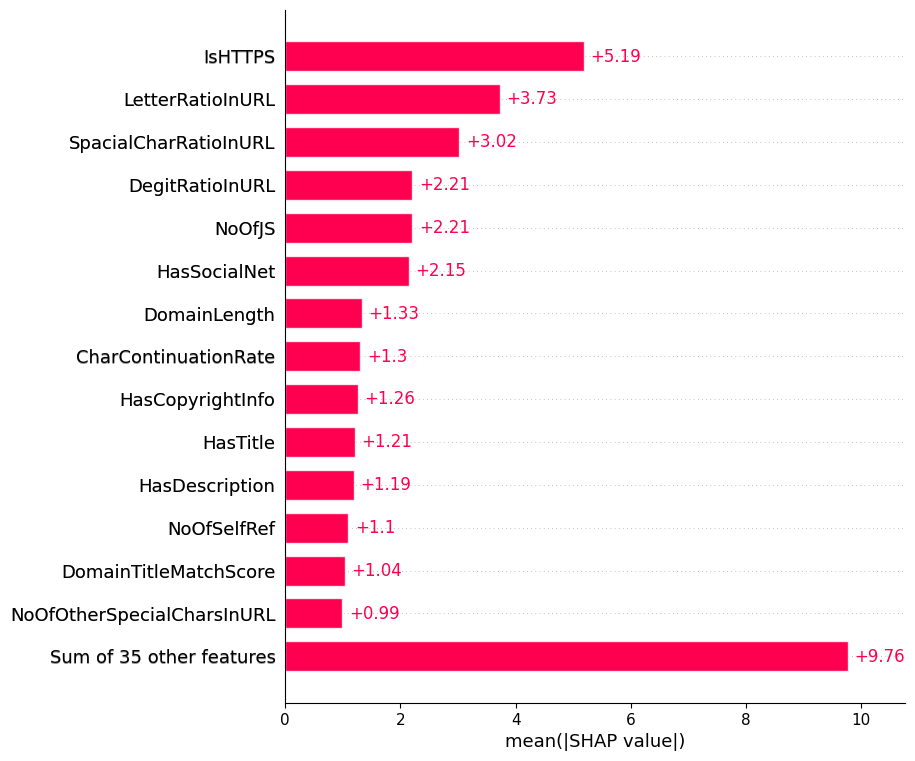

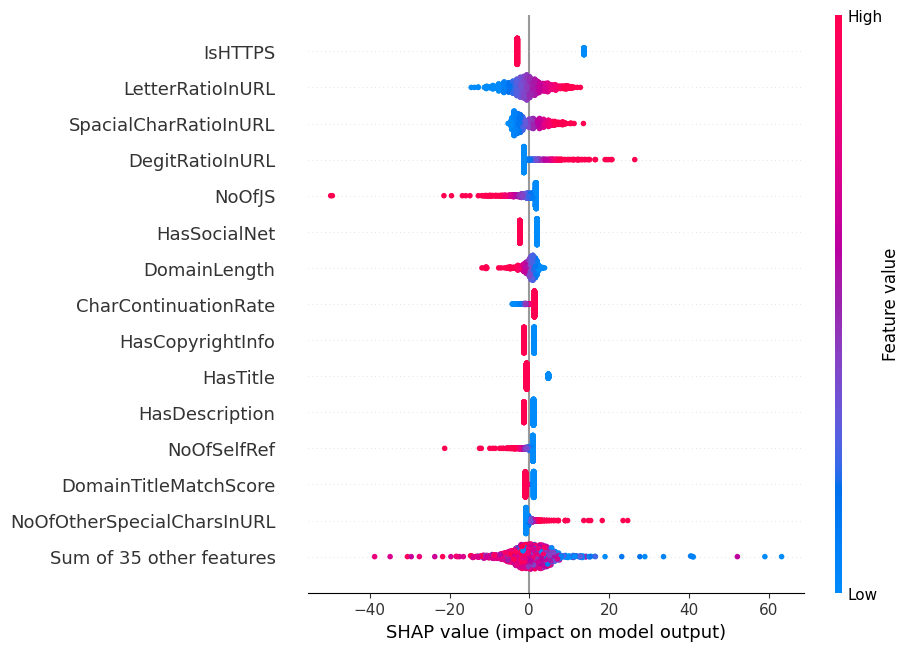

In [35]:
import shap

# Utilisation du modèle M3_L2_C1 récupéré depuis le dictionnaire des modèles entraînés
model_l2 = models['M3_L2_C1']

# Utilisation de shap.Explainer (plus robuste et universel que LinearExplainer)
explainer = shap.Explainer(model_l2, X_train_scaled)
shap_values = explainer(X_test_scaled.iloc[:1000])

# Affichage des graphiques globaux
shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

Aucun Faux Positif (FP) trouvé dans cet échantillon de 1000 lignes du fait de la très haute précision du modèle !

--- Graphique pour : TP (Phishing détecté) (index 2) ---


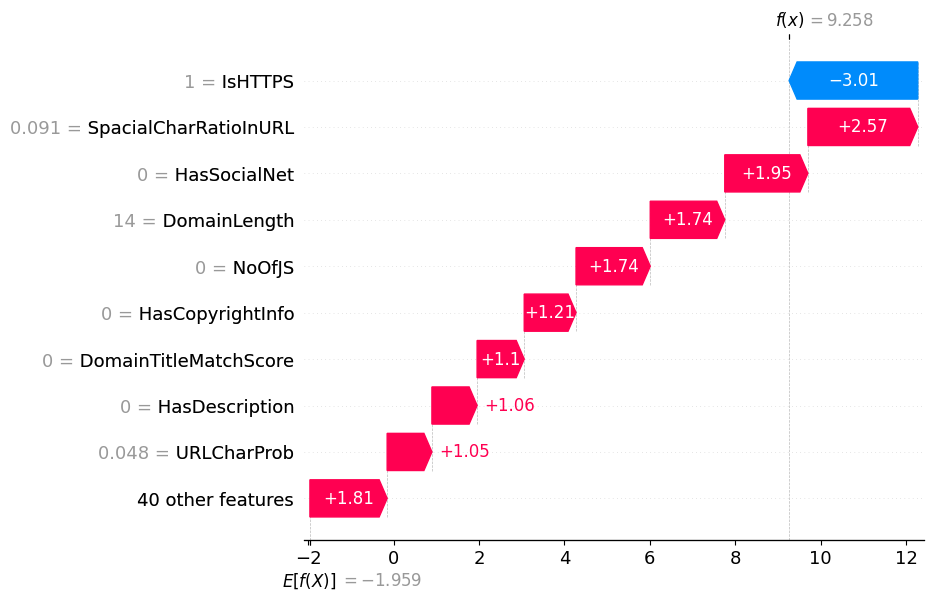


--- Graphique pour : TN (Légitime détecté) (index 0) ---


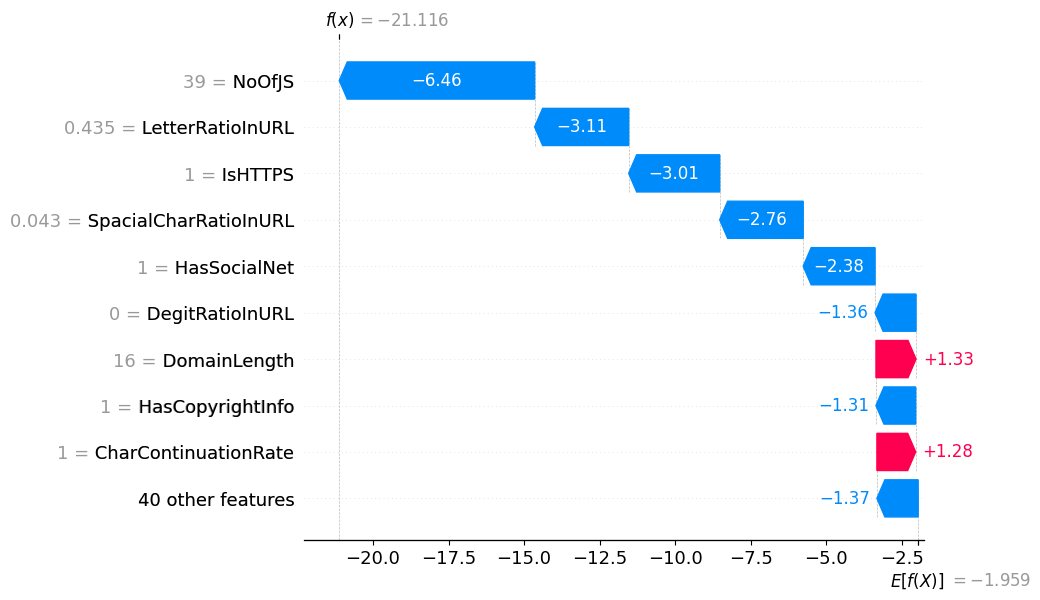

In [36]:
import numpy as np
X_sample = X_test.iloc[:1000]
y_sample = y_test.iloc[:1000].values
proba_s = model_l2.predict_proba(X_test_scaled.iloc[:1000])[:, 1]
pred_s = (proba_s >= 0.5).astype(int)

# Extraction des indices avec vérification de présence
tp_indices = np.where((y_sample == 1) & (pred_s == 1))[0]
tn_indices = np.where((y_sample == 0) & (pred_s == 0))[0]
fp_indices = np.where((y_sample == 0) & (pred_s == 1))[0]

cases = []
if len(tp_indices) > 0:
    cases.append(("TP (Phishing détecté)", tp_indices[0]))
if len(tn_indices) > 0:
    cases.append(("TN (Légitime détecté)", tn_indices[0]))
if len(fp_indices) > 0:
    cases.append(("FP (Fausse alerte)", fp_indices[0]))
else:
    print("Aucun Faux Positif (FP) trouvé dans cet échantillon de 1000 lignes du fait de la très haute précision du modèle !")

# Remplacement par les valeurs non-normalisées pour lisibilité du graphique
shap_values.data = X_sample.values

for name, i in cases:
    print(f"\n--- Graphique pour : {name} (index {i}) ---")
    shap.plots.waterfall(shap_values[i], max_display=10)

In [37]:
proba_full = model_l2.predict_proba(X_test_scaled)[:, 1]

rows = []
for tau in [0.20, 0.50, 0.85]:                     # LOOP over thresholds
    pred = (proba_full >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "tau": tau, "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })
pd.DataFrame(rows)

,tau,TP,TN,FP,FN,Precision,Recall,F1
0,0.20,25221,33682,31,15,0.998772,0.999406,0.999089
1,0.50,25208,33703,10,28,0.999603,0.998890,0.999247
2,0.85,25172,33713,0,64,1.000000,0.997464,0.998730
